# Pelota de Tenis

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use('bmh')

## Modelado y simulación de la trayectoria del balón


### Parámetros

In [18]:
ARCHIVO = "datos/tenis.csv"

m   = 0.0593      # masa del balón[kg]
D   = 0.064      # diámetro del balón [m]
A   = np.pi*(D/2)**2  # área transversal [m^2]
C   = 0.6        # coeficiente de arrastre (tenis)
rho = 1.225         # densidad del aire [kg/m^3]
g   = 9.8           # aceleración de gravedad [m/s^2]
B   = 0.5*C*rho*A   # Ec. (3)

FRAC_AJUSTE = 0.4  
DT = 0.0005     

REFERENCIA_PIXELES = 542
REFERENCIA_METROS = 1.75  

### Procesamiento del CSV

In [19]:
df = pd.read_csv(ARCHIVO)
df.columns = ["t", "x_px", "y_px", "vx_app", "vy_app"]  

t = df["t"].to_numpy() - df["t"].iloc[0]
x_px = df["x_px"].to_numpy() - df["x_px"].iloc[0]       
y_px = df["y_px"].to_numpy() - df["y_px"].iloc[0]

PX_POR_M = REFERENCIA_PIXELES / REFERENCIA_METROS

print(f"Escala: {PX_POR_M:.1f} px/m")

x_exp = x_px / PX_POR_M
y_exp = y_px / PX_POR_M


Escala: 309.7 px/m


### Estimación de las velocidades iniciales

In [20]:
N = max(8, int(FRAC_AJUSTE * len(t)))
vx0 = np.polyfit(t[:N], x_exp[:N], 2)[1]
vy0 = np.polyfit(t[:N], y_exp[:N], 2)[1]

print(f"Puntos utilizados para el ajuste: {N}")
print(f"Velocidad inicial: vx0 = {vx0:.3f} m/s")
print(f"vy0 = {vy0:.3f} m/s")
print(f"|v0| = {np.hypot(vx0, vy0):.3f} m/s")


Puntos utilizados para el ajuste: 53
Velocidad inicial: vx0 = 2.882 m/s
vy0 = 5.867 m/s
|v0| = 6.536 m/s


### Simulación: Método de Euler

In [21]:
def simular(vx0, vy0, t_max, con_roce=True, dt=DT, b_val=None):
    n = int(np.ceil(t_max / dt)) + 1
    ts = np.arange(n) * dt
    x = np.zeros(n)
    y = np.zeros(n)
    vx = np.zeros(n)
    vy = np.zeros(n)

    vx[0], vy[0] = vx0, vy0
    b = (B if b_val is None else b_val) if con_roce else 0.0

    for i in range(n - 1):
        v = np.hypot(vx[i], vy[i])
        ax = -b * v * vx[i] / m
        ay = -b * v * vy[i] / m - g
        x[i+1] = x[i] + vx[i] * dt
        y[i+1] = y[i] + vy[i] * dt
        vx[i+1] = vx[i] + ax * dt
        vy[i+1] = vy[i] + ay * dt
    return ts, x, y

t_max = t[-1]
ts_r, x_r, y_r = simular(vx0, vy0, t_max, con_roce=True)
ts_s, x_s, y_s = simular(vx0, vy0, t_max, con_roce=False)


### Gráfico

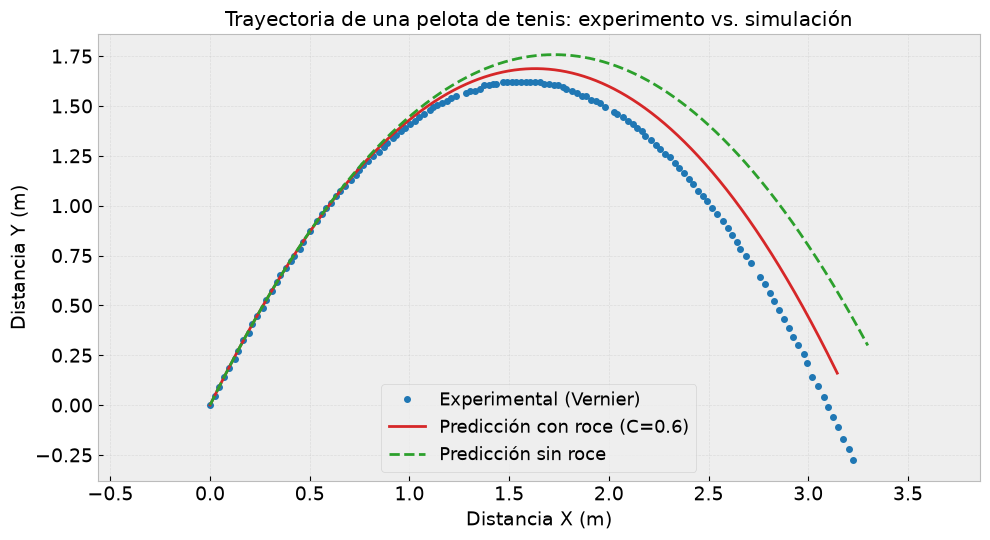

In [22]:

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(x_exp, y_exp, "o", ms=4, color="tab:blue", label="Experimental (Vernier)")
ax.plot(x_r, y_r, "-", lw=2, color="tab:red", label=f"Predicción con roce (C={C})")
ax.plot(x_s, y_s, "--", lw=2, color="tab:green", label="Predicción sin roce")
ax.set_xlabel("Distancia X (m)", fontsize=14)
ax.set_ylabel("Distancia Y (m)", fontsize=14)
ax.set_title("Trayectoria de una pelota de tenis: experimento vs. simulación")
ax.set_aspect("equal", adjustable="datalim")
ax.grid(alpha=0.3)
ax.tick_params(axis="both", labelsize=14)
ax.legend(fontsize=13)
fig.tight_layout()
plt.show()

## Prueba de convergencia temporal de Euler

In [ ]:
pasos = [0.004, 0.002, 0.001, 0.0005, 0.00025]
diferencias = []


for i in range(len(pasos) - 1):
    dt1 = pasos[i]    
    dt2 = pasos[i + 1] 
    _, x1, y1 = simular(vx0, vy0, t_max, con_roce=True, dt=dt1)
    _, x2, y2 = simular(vx0, vy0, t_max, con_roce=True, dt=dt2)
    n = min(len(x1), len(x2[::2]))
    D_conv = np.sqrt(np.mean((x1[:n] - x2[::2][:n])**2 + (y1[:n] - y2[::2][:n])**2))

    diferencias.append(D_conv)
    print(f"dt = {dt1:.5f} vs {dt2:.5f} s: RMS = {D_conv:.6f} m")


print("\nOrden de convergencia:")

for i in range(len(diferencias) - 1):
    p = np.log2(diferencias[i] / diferencias[i + 1])
    print(f"p = {p:.3f}")

dt = 0.00400 vs 0.00200 s: RMS = 0.006206 m
dt = 0.00200 vs 0.00100 s: RMS = 0.003101 m
dt = 0.00100 vs 0.00050 s: RMS = 0.001550 m
dt = 0.00050 vs 0.00025 s: RMS = 0.000775 m

Orden de convergencia:
p = 1.001
p = 1.000
p = 1.000


## Propagación de errores y gráficos

### Incertidumbres

In [ ]:
delta_d = 0.001 #incertidumbre diámetro tenis
delta_C = 0.05 #incertidumbre coeficiente de arrastre tenis (literatura)
delta_p = 2.0

P, delta_P = 100080.0, 10.0
Temp_C, delta_T = 15.0, 1.0

delta_A = 2 * A * delta_d / D
delta_rho = rho * np.hypot(delta_P / P, delta_T / (Temp_C + 273.15))
delta_B = B * np.sqrt((delta_C / C)**2 + (delta_rho / rho)**2 + (delta_A / A)**2)

                      
#Incertidumbre de posiciones y velocidad inicial
err_S = np.sqrt(2) * delta_p / REFERENCIA_PIXELES
err_px = np.sqrt(2) * delta_p / PX_POR_M

dx_exp = np.hypot(err_px, x_exp * err_S)
dy_exp = np.hypot(err_px, y_exp * err_S)

cov_x = np.polyfit(t[:N], x_exp[:N], 2, cov=True)[1]
cov_y = np.polyfit(t[:N], y_exp[:N], 2, cov=True)[1]

dvx = np.sqrt(cov_x[1, 1])
dvy = np.sqrt(cov_y[1, 1])

v0 = np.hypot(vx0, vy0)
dv0 = np.hypot(vx0 * dvx, vy0 * dvy) / v0


#Banda de incertidumbre de B
_, xb, yb = simular(vx0, vy0, t_max, b_val=B - delta_B)
_, xa, ya = simular(vx0, vy0, t_max, b_val=B + delta_B)

yb = np.interp(x_r, xb, yb, left=np.nan, right=np.nan)
ya = np.interp(x_r, xa, ya, left=np.nan, right=np.nan)

y_inf = np.minimum(yb, ya)
y_sup = np.maximum(yb, ya)

### Error entre simulación y experimento

In [25]:
def rmse_2d(ts, xs, ys):
    xi = np.interp(t, ts, xs)
    yi = np.interp(t, ts, ys)
    return np.sqrt(np.mean((xi - x_exp)**2 + (yi - y_exp)**2))

print(f"B = {B:.6f} ± {delta_B:.6f} kg/m")
print(f"|v0| = {v0:.3f} ± {dv0:.3f} m/s")
print(f"RMSE con roce = {rmse_2d(ts_r, x_r, y_r):.4f} m")
print(f"RMSE sin roce = {rmse_2d(ts_s, x_s, y_s):.4f} m")

B = 0.001182 ± 0.000105 kg/m
|v0| = 6.536 ± 0.033 m/s
RMSE con roce = 0.1665 m
RMSE sin roce = 0.2499 m


### Gráficos

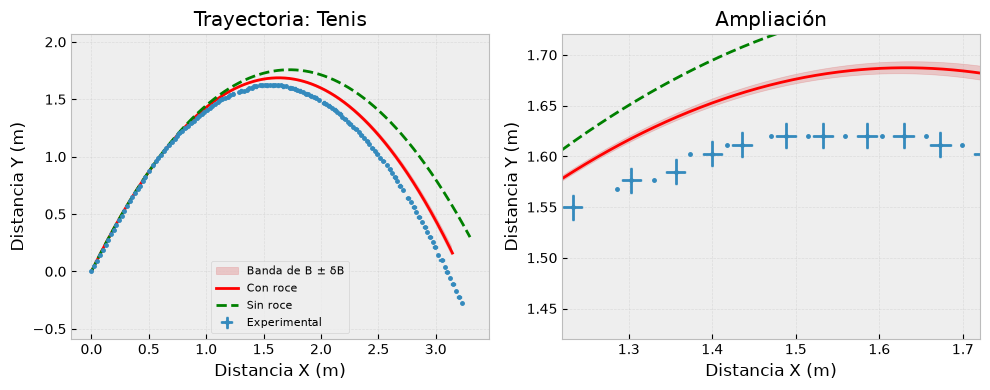

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax in axes:
    ax.fill_between(x_r, y_inf, y_sup, color="tab:red", alpha=0.2, label="Banda de B ± δB")
    ax.errorbar(x_exp, y_exp, xerr=dx_exp, yerr=dy_exp, fmt="o", ms=2.5, capsize=1, errorevery=2, label="Experimental")
    ax.plot(x_r, y_r, "r-", label="Con roce")
    ax.plot(x_s, y_s, "g--", label="Sin roce")
    ax.set(xlabel="Distancia X (m)", ylabel="Distancia Y (m)")
    ax.grid(alpha=0.3)

axes[0].set_title("Trayectoria: Tenis")
axes[0].set_aspect("equal", adjustable="datalim")
axes[0].legend(fontsize=8)
xm = x_exp[np.argmax(y_exp)]
ym = max(y_exp)
axes[1].set(xlim=(xm - 0.25, xm + 0.25), ylim=(ym - 0.2, ym + 0.10), title="Ampliación")
plt.tight_layout()
plt.show()